In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('placement.csv')

In [19]:
df.head()
df.shape

(200, 2)

Text(0, 0.5, 'Package in LPA')

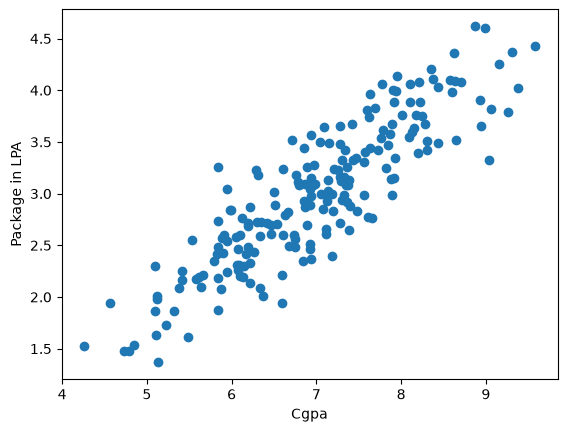

In [14]:
plt.scatter(df['cgpa'] , df['package'])
plt.xlabel('Cgpa')
plt.ylabel('Package in LPA')

In [7]:
from sklearn.model_selection import train_test_split

In [29]:
X = df[['cgpa']]

# we are using double square bracket because , the linear regression function 
# requires a 2D input table 
# The above one is a Dataframe not a series
# It is a single column dataframe

In [30]:
y = df['package']
# it is a series

In [63]:
X_train , X_test , y_train , y_test = train_test_split(X, y , test_size=0.2 ,random_state=2)

In [32]:
X_train.shape

(160, 1)

In [33]:
X_test.shape

(40, 1)

In [34]:
from sklearn.linear_model import LinearRegression

In [35]:
lr = LinearRegression()

In [64]:
lr.fit(X_train , y_train)

# the model is now trained , now we can test it

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.56]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.8961
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [65]:
lr.coef_

# it is the value of m in the equation (y = mx + c)

array([0.55795197])

In [66]:
lr.intercept_

# it is the value of c in the equation in( y + mx + c)

np.float64(-0.8961119222429126)

In [67]:
lr.predict(X_test)

# this is the predited value of all students (predicted package)
# also denoted as y^    in the equation

array([3.89111601, 3.09324469, 2.38464568, 2.57434935, 1.6537286 ,
       1.77647803, 2.07219258, 2.93143862, 3.76278706, 2.93701814,
       4.09197872, 3.51170867, 2.97049525, 2.40138424, 3.18809652,
       3.46707251, 1.94386362, 3.24389172, 2.97607477, 3.41685683,
       2.55761079, 3.16577844, 2.85890486, 3.12114229, 3.68467378,
       2.8700639 , 3.49497011, 3.34432308, 3.91901361, 1.96060218,
       3.65119666, 3.2104146 , 3.74046898, 2.7863711 , 2.78079158,
       3.27178932, 3.52844723, 2.61340599, 2.65804215, 2.71383735])

In [68]:
# lr.predict(X_test.iloc[0])             # this will send a series to linear regression (expects a dataframe)

lr.predict(X_test.iloc[[0]])             # This will sends a dataframe
lr.predict(X_test.iloc[0].values.reshape(1,1))             # This will also sends a dataframe

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([3.89111601])

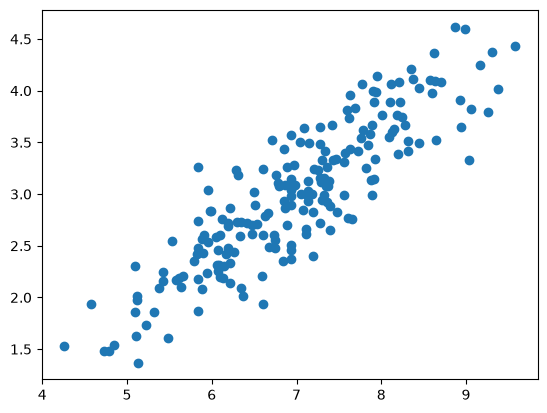

In [69]:
plt.scatter(df['cgpa'] , df['package'])

# scatter plot of original data

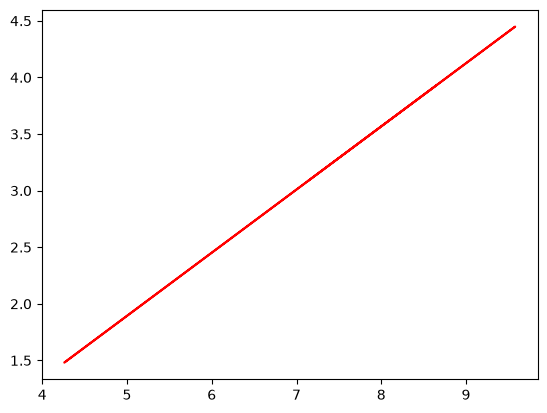

In [70]:
plt.plot(X_train,lr.predict(X_train),color='red')

# line plot of the actual and predicted data

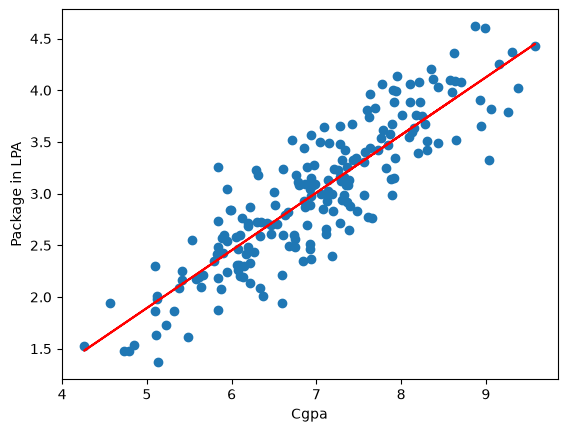

In [71]:
# now we are combining both of them

plt.scatter(df['cgpa'] , df['package'])
plt.xlabel('Cgpa')
plt.ylabel('Package in LPA')

plt.plot(X_train , lr.predict(X_train) , color = 'red')


# now by seeing this u can see the best fit line of the given table